In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


In [9]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
%pip install pandas numpy matplotlib seaborn plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
df = pd.read_csv("swiggy_data.csv")

In [8]:
df.head()

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
0,Karnataka,Bengaluru,29-06-2025,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0
1,Karnataka,Bengaluru,03-04-2025,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25
2,Karnataka,Bengaluru,15-01-2025,Srinidhi Sagar Deluxe,Kengeri,Recommended,Chow Chow Bath,117.0,4.7,48
3,Karnataka,Bengaluru,17-04-2025,Srinidhi Sagar Deluxe,Kengeri,Recommended,Kesari Bath,65.0,4.6,65
4,Karnataka,Bengaluru,13-03-2025,Srinidhi Sagar Deluxe,Kengeri,Recommended,Mix Raitha,130.0,4.0,0


In [19]:
df.tail()

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
197425,Sikkim,Gangtok,25-01-2025,Mama's Kitchen,Gangtok,Momos,Soya cheese chilli momo ...,112.0,4.4,0
197426,Sikkim,Gangtok,02-07-2025,Mama's Kitchen,Gangtok,Momos,Kurkure momo fried ...,140.0,4.4,0
197427,Sikkim,Gangtok,25-03-2025,Mama's Kitchen,Gangtok,Momos,Chilli cheese momo,126.0,4.4,0
197428,Sikkim,Gangtok,26-03-2025,Mama's Kitchen,Gangtok,Momos,Veg Momos (8 Pc),85.0,4.4,0
197429,Sikkim,Gangtok,27-03-2025,Mama's Kitchen,Gangtok,Momos,Soya Momo,100.0,4.4,0


In [23]:
print("no of rows",df.shape[0])

no of rows 197430


In [25]:
print("no of column",df.shape[1])

no of column 10


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 197430 entries, 0 to 197429
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   State            197430 non-null  str    
 1   City             197430 non-null  str    
 2   Order Date       197430 non-null  str    
 3   Restaurant Name  197430 non-null  str    
 4   Location         197430 non-null  str    
 5   Category         197430 non-null  str    
 6   Dish Name        197430 non-null  str    
 7   Price (INR)      197430 non-null  float64
 8   Rating           197430 non-null  float64
 9   Rating Count     197430 non-null  int64  
dtypes: float64(2), int64(1), str(7)
memory usage: 32.7 MB


In [29]:
df.info


<bound method DataFrame.info of             State       City  Order Date           Restaurant Name  \
0       Karnataka  Bengaluru  29-06-2025  Anand Sweets & Savouries   
1       Karnataka  Bengaluru  03-04-2025     Srinidhi Sagar Deluxe   
2       Karnataka  Bengaluru  15-01-2025     Srinidhi Sagar Deluxe   
3       Karnataka  Bengaluru  17-04-2025     Srinidhi Sagar Deluxe   
4       Karnataka  Bengaluru  13-03-2025     Srinidhi Sagar Deluxe   
...           ...        ...         ...                       ...   
197425     Sikkim    Gangtok  25-01-2025            Mama's Kitchen   
197426     Sikkim    Gangtok  02-07-2025            Mama's Kitchen   
197427     Sikkim    Gangtok  25-03-2025            Mama's Kitchen   
197428     Sikkim    Gangtok  26-03-2025            Mama's Kitchen   
197429     Sikkim    Gangtok  27-03-2025            Mama's Kitchen   

                    Location     Category  \
0       Rajarajeshwari Nagar        Snack   
1                    Kengeri  Recomme

In [35]:
df.dtypes

State                  str
City                   str
Order Date             str
Restaurant Name        str
Location               str
Category               str
Dish Name              str
Price (INR)        float64
Rating             float64
Rating Count         int64
dtype: object

In [19]:
df.describe()

,Price (INR),Rating,Rating Count
count,197430.000000,197430.000000,197430.000000
mean,268.512920,4.341582,28.321805
std,219.338363,0.422585,87.542593
min,0.950000,1.500000,0.000000
25%,139.000000,4.300000,0.000000
50%,229.000000,4.400000,2.000000
75%,329.000000,4.500000,15.000000
max,8000.000000,5.000000,999.000000


#KPI'S

In [38]:
total_sales = df['Price (INR)'].sum()
print(total_sales)

53012505.769999996


### Average Rating


In [44]:
average_rating = df['Rating'].mean()
print(average_rating)

4.341581826470141


### Average Order Value

In [49]:
average_order = df['Price (INR)'].mean()
print(average_order)

268.51291987033375


### Rating Count

In [53]:
rating_count = df['Rating Count'].sum()
print(rating_count)

5591574


### Total Orders

In [57]:
print("Total order",len(df))

Total order 197430


### Chart Design

C:\Users\harsh\AppData\Local\Temp\ipykernel_10580\3139832238.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Order Date'] = pd.to_datetime(df['Order Date'])


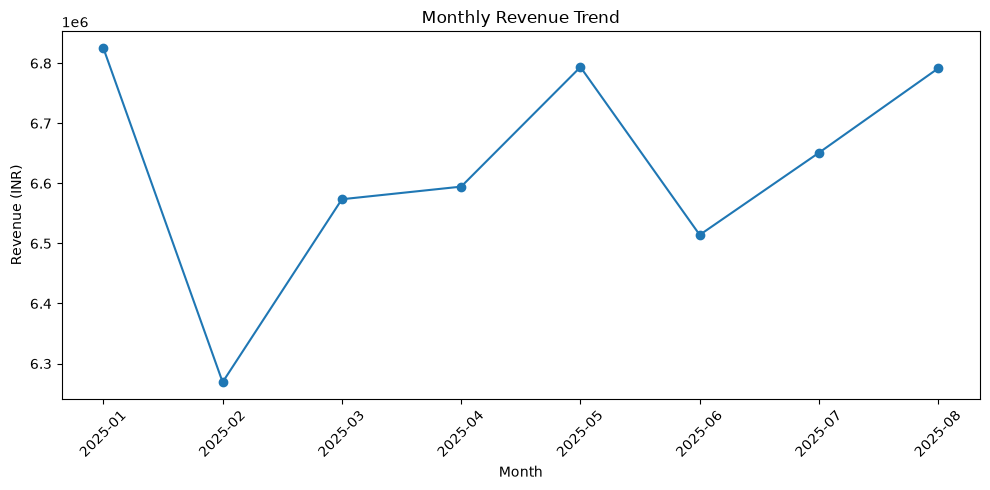

In [10]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

df['YearMonth'] = df['Order Date'].dt.to_period("M").astype(str)

monthly_revenue = df.groupby('YearMonth')['Price (INR)'].sum().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue['YearMonth'], monthly_revenue['Price (INR)'], marker='o')

plt.xticks(rotation=45)
plt.xlabel('Month')
plt.ylabel('Revenue (INR)')
plt.title('Monthly Revenue Trend')

plt.tight_layout()
plt.show()

### Daily Sales Trend

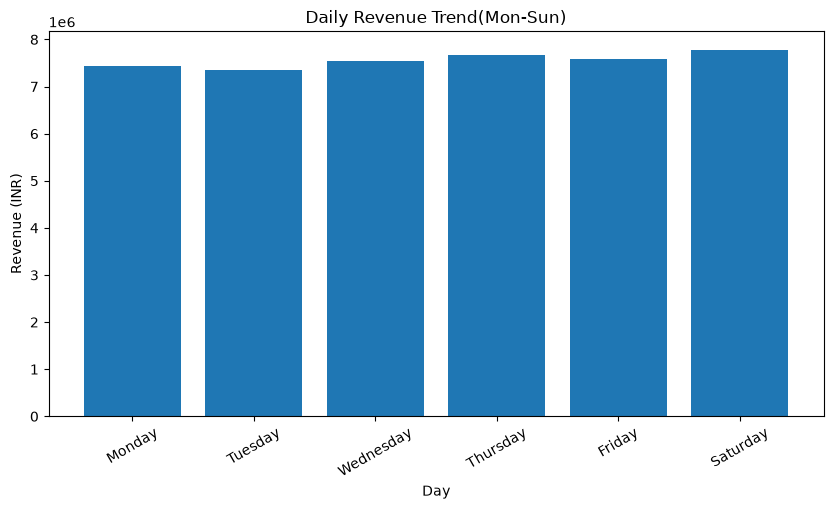

In [17]:
df['DayName'] = pd.to_datetime(df['Order Date']).dt.day_name()

daily_revenue = (
    df.groupby('DayName')['Price (INR)']
      .sum()
      .reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday'])
)

plt.figure(figsize=(10,5))
plt.bar(daily_revenue.index,daily_revenue.values)
plt.title('Daily Revenue Trend(Mon-Sun)')
plt.xlabel('Day')
plt.ylabel('Revenue (INR)')
plt.xticks(rotation=30)

plt.show()


### Total sales by food type (NON-Veg vs Veg)

In [32]:
non_veg_keyword = [
    'chicken','egg','fish','mutton',
    'prawn','biryani','kabab','non-veg'
]
df['Food Category'] = np.where(
    df['Dish Name'].str.lower().str.contains("|".join(non_veg_keyword),na=False),
    'Non-Veg',
    'Veg'
)

In [36]:
food_revenue = (
    df.groupby('Food Category')['Price (INR)']
      .sum()
      .reset_index()
)

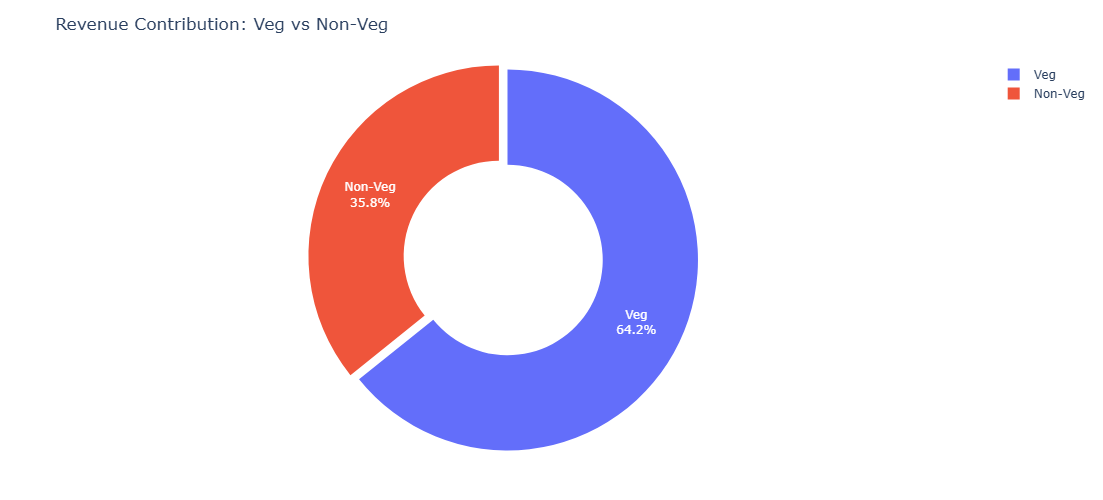

In [44]:
fig = px.pie(
    food_revenue,
    values='Price (INR)',
    names='Food Category',
    hole=0.5,
    title='Revenue Contribution: Veg vs Non-Veg'
)

fig.update_traces(
    textinfo='percent+label',
    pull=(0.05, 0)
)

fig.update_layout(
    height=500,
    margin=dict(t=60, b=40, l=40, r=40)
)

fig.show()

### Total sales by state

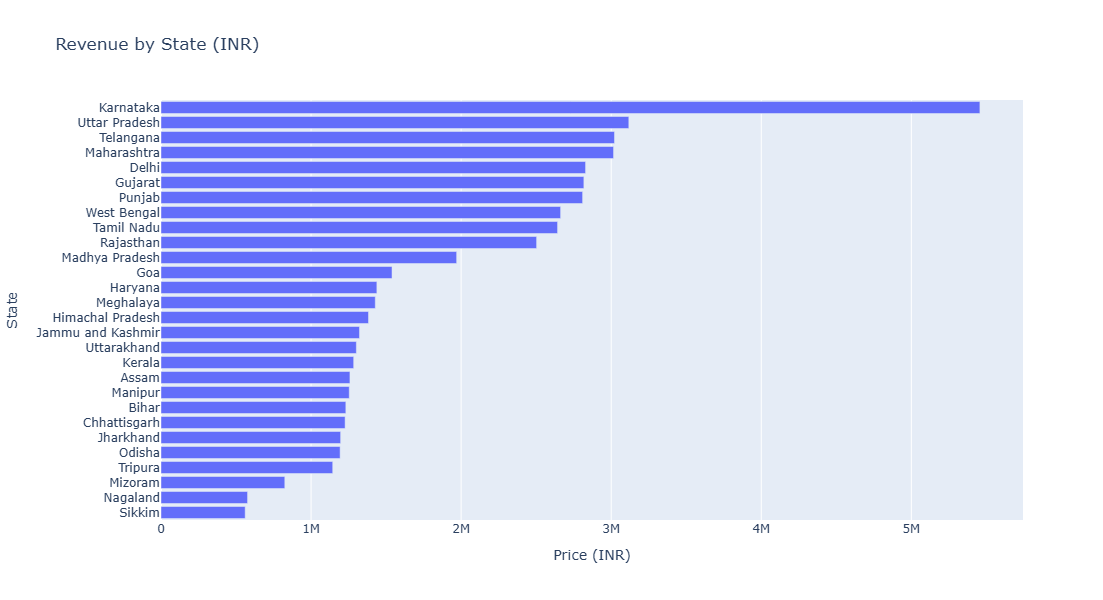

In [51]:
fig = px.bar(
    df.groupby("State", as_index=False)['Price (INR)'].sum()
      .sort_values('Price (INR)', ascending=False),
    x='Price (INR)',
    y='State',
    orientation='h',
    title='Revenue by State (INR)'
)

fig.update_layout(
    height=600,
    yaxis=dict(autorange="reversed")
)

fig.show()

### Quarterly Performance Summary

In [57]:
df['Order_Date'] = pd.to_datetime(df['Order Date'])

df['Quarter'] = df['Order_Date'].dt.to_period('Q').astype(str)

Quarterly_summary = (
    df.groupby('Quarter', as_index=False)
      .agg(
          Total_Sales=('Price (INR)', 'sum'),
          Avg_Rating=('Rating', 'mean'),
          Total_Orders=('Order_Date', 'count')
      )
      .sort_values('Quarter')
)

Quarterly_summary['Total_Sales'] = Quarterly_summary['Total_Sales'].round(0)
Quarterly_summary['Avg_Rating'] = Quarterly_summary['Avg_Rating'].round(2)

Quarterly_summary

,Quarter,Total_Sales,Avg_Rating,Total_Orders
0,2025Q1,19667822.0,4.34,73096
1,2025Q2,19902257.0,4.34,74163
2,2025Q3,13442427.0,4.34,50171


### TOP 5 Cities by sales

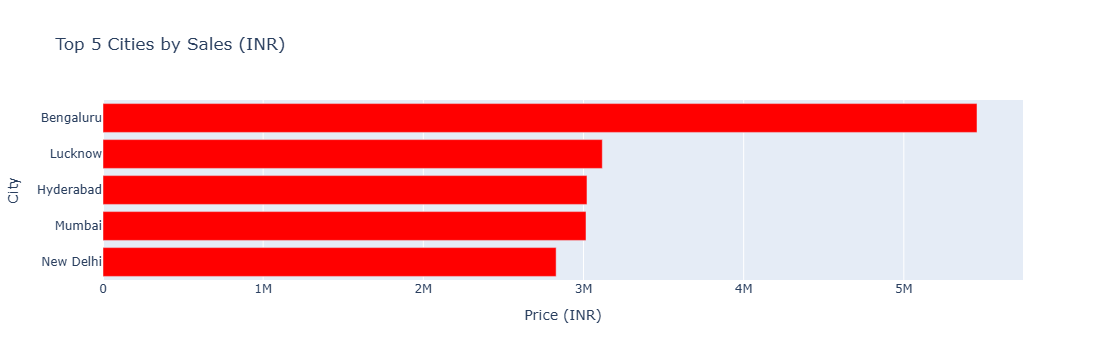

In [62]:
top_5_cities = (
    df.groupby('City')['Price (INR)']
      .sum()
      .nlargest(5)
      .sort_values()
      .reset_index()
)

fig = px.bar(
    top_5_cities,
    x='Price (INR)',
    y='City',
    orientation='h',
    title='Top 5 Cities by Sales (INR)',
    color_discrete_sequence=['red']
)

fig.show()

In [64]:
pip install psycopg2-binary sqlalchemy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [78]:
import pandas as pd
from sqlalchemy import create_engine

# Step 1: PostgreSQL connection details
username = "postgres"
password = "admin123"
host = "localhost"
port = 5432
database = "Swiggy_data"

# Step 2: Create database connection
engine = create_engine(
    f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}"
)

# Step 3: Load DataFrame into PostgreSQL
table_name = "swiggy"

df.to_sql(
    table_name,
    engine,
    if_exists="replace",
    index=False
)

print(
    f"Data successfully loaded into table '{table_name}' "
    f"in database '{database}'."
)

Data successfully loaded into table 'swiggy' in database 'Swiggy_data'.


In [79]:
pip install pandas sqlalchemy psycopg2-binary

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [84]:
import pandas as pd
from sqlalchemy import create_engine

# Step 1: Load CSV file into DataFrame
df = pd.read_csv("swiggy_data.csv")

# Check the data
print(df.head())

# Step 2: PostgreSQL connection details
username = "postgres"
password = "postgres123"
host = "localhost"
port = "5432"
database = "Swiggy_data"

# Step 3: Create connection
engine = create_engine(
    f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}"
)

# Step 4: Create/replace table
table_name = "swiggy"

df.to_sql(
    table_name,
    engine,
    if_exists="replace",
    index=False
)

print(f"Data successfully loaded into table '{table_name}'")

       State       City  Order Date           Restaurant Name  \
0  Karnataka  Bengaluru  29-06-2025  Anand Sweets & Savouries   
1  Karnataka  Bengaluru  03-04-2025     Srinidhi Sagar Deluxe   
2  Karnataka  Bengaluru  15-01-2025     Srinidhi Sagar Deluxe   
3  Karnataka  Bengaluru  17-04-2025     Srinidhi Sagar Deluxe   
4  Karnataka  Bengaluru  13-03-2025     Srinidhi Sagar Deluxe   

               Location     Category             Dish Name  Price (INR)  \
0  Rajarajeshwari Nagar        Snack  Butter Murukku-200gm        133.9   
1               Kengeri  Recommended            Badam Milk         52.0   
2               Kengeri  Recommended        Chow Chow Bath        117.0   
3               Kengeri  Recommended           Kesari Bath         65.0   
4               Kengeri  Recommended            Mix Raitha        130.0   

   Rating  Rating Count  
0     4.0             0  
1     4.5            25  
2     4.7            48  
3     4.6            65  
4     4.0             0  
Da